# Where do hippocampal neurons fire along this maze?

**Question:** How does firing rate vary along the maze, and which arm ends
does the rat visit in succession?

Estimate spatial firing-rate maps from one hippocampal recording, then use
the same position samples to describe movement between arm ends. We will
distinguish changes in firing rate from uneven time spent along the maze.

**You will need:** Spike times, position samples and a maze layout, all
supplied with this example. The first download needs an internet connection
and about 75 MB of disk space. No previous notebook variables are needed.

**Estimated time**: 25-30 minutes

**Prerequisites**: [Spatial rate maps](02_spatial_rate_maps.ipynb) and
[Trajectories and behavior](03_trajectories_and_behavior.ipynb).

The public [J16 archive](https://doi.org/10.5281/zenodo.23020757) contains
203 hippocampal spike trains, preprocessed 500 Hz tracking and a track graph.
Positions are in centimeters and timestamps are in seconds. Tracking was
already smoothed, upsampled and assigned to the track. We start with these
processed data rather than processing camera detections.
The archive does not retain original unit identifiers or trial and reward
labels. We can describe firing and movement, but cannot identify rewarded
trials or the animal's intended goal. Unit numbers below are array indices
within this archive.
See the [data guide](https://github.com/edeno/neurospatial/blob/main/data/README.md)
for study attribution, CC BY 4.0 licensing and preprocessing details.

In [1]:
import importlib.util
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Circle

from neurospatial import Environment, Regions
from neurospatial.behavior import (
    detect_region_visits,
    path_progress,
    region_transitions,
)
from neurospatial.encoding import compute_spatial_rates

_here = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
_root = next(
    path
    for path in (_here, *_here.parents)
    if (path / "data" / "load_bandit_data.py").exists()
)
sys.path.insert(0, str(_root / "examples"))
from _style import apply_style

apply_style(figsize=(10, 5))
_spec = importlib.util.spec_from_file_location(
    "load_bandit_data", _root / "data" / "load_bandit_data.py"
)
if _spec is None or _spec.loader is None:
    raise ImportError("Could not import the recording helper from data/.")
_loader = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(_loader)

## 1. Load spikes and position on the same clock

The first run downloads about 75 MB. Later runs verify and reuse the cached
file. For offline work, run `uv run python data/load_bandit_data.py` beforehand.
Both measurements use the recording clock. Subtract the first tracking time
from both so that plots start at zero without shifting spikes relative to
position. A gap longer than 0.5 s will separate observed stretches of movement.

In [2]:
archive = _loader.fetch_bandit_data(_root / "data")
recording = _loader.load_neural_recording_from_files(
    _root / "data", "j1620210710_02_r1"
)
tracking = recording["position_info"]
origin = float(tracking.index[0])
times = tracking.index.to_numpy(dtype=float) - origin
positions = tracking[["head_position_x", "head_position_y"]].to_numpy()
spike_times = [train - origin for train in recording["spike_times"]]
unit_ids = np.arange(len(spike_times))
spike_counts = np.array([len(train) for train in spike_times])
max_gap = 0.5  # seconds; do not join movement or assign spikes across longer gaps
recording_window = (float(times[0]), float(times[-1]))
print(f"Loaded verified recording: {archive.name}")
print(f"{len(times):,} samples, {len(unit_ids)} units, {times[-1] / 60:.1f} minutes")
print(f"Tracking gaps > {max_gap:g} s: {np.count_nonzero(np.diff(times) > max_gap)}")

Loaded verified recording: j1620210710_02_r1_figure04_inputs.npz
709,321 samples, 203 units, 23.6 minutes
Tracking gaps > 0.5 s: 0


## 2. Map the track and mark the arm ends

Divide the known track into 2 cm bins. The graph records which track segments
connect, so later smoothing follows the maze rather than crossing open space.
The plot below checks that the position samples follow this layout.

Mark an 8 cm zone around each arm end to define entries consistently. These
are analysis regions that we choose, not measured reward-well boundaries.

`track_width` is the full width of the track around its centerline. A
position farther than half of it from every segment is off the track: it
gets no bin and adds no occupancy or spikes. For your own maze, start from
the measured corridor width plus the tracking error, then check where the
excluded samples are, as below. This archive does not record the maze's
width, so we first measure how far the tracked head is from the centerline.

In [3]:
graph = recording["track_graph"]
endpoint_nodes = sorted(node for node in graph if graph.degree(node) == 1)
centerline_only = Environment.from_graph(
    graph,
    edge_order=recording["linear_edge_order"],
    edge_spacing=recording["linear_edge_spacing"],
    bin_size=2.0,
)
# to_linear projects every position onto the centerline, however far off it.
projected = centerline_only.linear_to_nd(centerline_only.to_linear(positions))
off_centerline = np.linalg.norm(positions - projected, axis=1)
arm_end_xy = np.array([graph.nodes[node]["pos"] for node in endpoint_nodes])
near_arm_end = (
    np.min(np.linalg.norm(positions[:, None] - arm_end_xy[None], axis=2), axis=1) < 20.0
)
beyond_corridor = off_centerline > 7.5  # outside a 15 cm corridor
print(
    f"Head positions more than 7.5 cm from the centerline: {beyond_corridor.mean():.1%}"
)
print(
    "Of those, within 20 cm of an arm end: "
    f"{(beyond_corridor & near_arm_end).sum() / beyond_corridor.sum():.0%}"
)
print(f"Farthest head position from the centerline: {off_centerline.max():.1f} cm")

Head positions more than 7.5 cm from the centerline: 16.1%
Of those, within 20 cm of an arm end: 74%
Farthest head position from the centerline: 20.4 cm


A 15 cm corridor would leave 16% of the samples off the track, three
quarters of them near the arm ends. The archive's centerline stops at the
end of each arm, short of the reward wells, and the head is over the wells
while the rat waits for reward. Those samples are the arm-end visits that
section 4 counts, so excluding them would remove the visits we want to
study. We therefore pass a footprint of 41 cm, which reaches the reward
wells past the ends of the centerline; on this archive it excludes no
sample. This is a choice for this archive's centerline, not a measured
corridor width: with your own maze, extend the graph to the reward wells and
pass the measured width, so that reflections and tracking jumps off the
track are excluded.

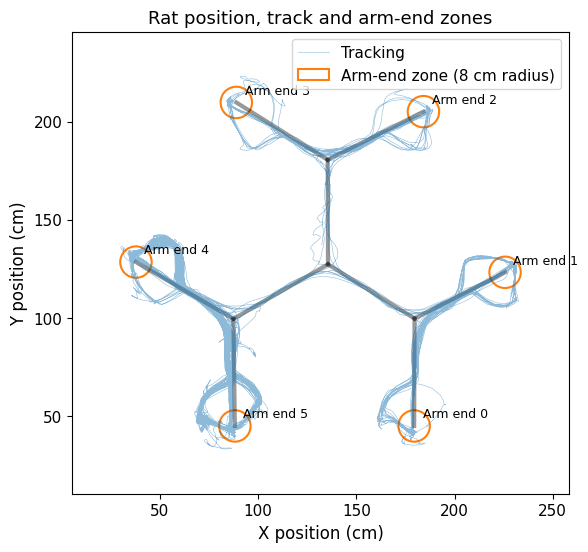

In [4]:
env = Environment.from_graph(
    graph,
    edge_order=recording["linear_edge_order"],
    edge_spacing=recording["linear_edge_spacing"],
    bin_size=2.0,
    track_width=41.0,  # cm; reaches the reward wells past the arm ends
    name="J16 maze",
)
env = env.with_metadata(units="cm")
arm_end_radius_cm = 8.0
arm_end_names = []
regions = Regions(env.regions.values())
for node in endpoint_nodes:
    name = f"arm_end_{node}"
    regions.buffer(
        np.asarray(graph.nodes[node]["pos"], dtype=float), arm_end_radius_cm, name
    )
    arm_end_names.append(name)
env = env.with_regions(regions)

fig, ax = plt.subplots(figsize=(7, 6))
for first, second in graph.edges:
    segment = np.array([graph.nodes[first]["pos"], graph.nodes[second]["pos"]])
    ax.plot(*segment.T, color="black", linewidth=3, alpha=0.4)
ax.plot(
    *positions[::40].T, color="tab:blue", linewidth=0.4, alpha=0.5, label="Tracking"
)
for index, node in enumerate(endpoint_nodes):
    center = np.asarray(graph.nodes[node]["pos"], dtype=float)
    ax.add_patch(
        Circle(
            center,
            arm_end_radius_cm,
            fill=False,
            color="tab:orange",
            linewidth=1.5,
            label="Arm-end zone (8 cm radius)" if index == 0 else None,
        )
    )
    ax.annotate(
        f"Arm end {node}", center, xytext=(6, 6), textcoords="offset points", fontsize=9
    )
ax.set(
    xlabel="X position (cm)",
    ylabel="Y position (cm)",
    title="Rat position, track and arm-end zones",
)
ax.margins(0.12)
ax.legend(loc="best")
ax.set_aspect("equal")
plt.show()

## 3. Where do these units fire?

Estimate firing rate by dividing spike counts by time spent in each location.
Smooth over 8 cm along the connected track and require at least 0.5 s of
occupancy per bin. Bins with less occupancy remain missing, rather than
appearing to have zero firing rate. These choices set the spatial detail that
we can interpret.

We assume spikes were recorded throughout the exported tracking period and
pass that interval as `spike_window`. The archive has no separate acquisition
intervals for individual units; use those intervals when your recording has
interruptions that are absent from tracking.

In [5]:
rates = compute_spatial_rates(
    env,
    spike_times,
    times,
    positions,
    unit_ids=unit_ids,
    bandwidth=8.0,
    min_occupancy=0.5,
    max_gap=max_gap,
    spike_window=recording_window,
)
print(f"Time assigned to track bins: {rates.occupancy.sum():.1f} s")
print(f"Bins with enough occupancy: {rates.spatial_support.sum()} / {env.n_bins}")
summary = pd.DataFrame(
    {
        "spike_count": spike_counts,
        "spatial_information_bits_per_spike": [
            rate.spatial_information() for rate in rates
        ],
    },
    index=pd.Index(rates.unit_ids, name="archive_unit_index"),
)
# Show three units with many spikes; this does not select for place fields.
example_units = summary.nlargest(3, "spike_count").index.to_numpy()
print(summary.loc[example_units].round(3).to_string())

Time assigned to track bins: 1418.6 s
Bins with enough occupancy: 173 / 248
                    spike_count  spatial_information_bits_per_spike
archive_unit_index                                                 
100                       63589                               0.028
178                       60932                               0.012
23                        56939                               0.027


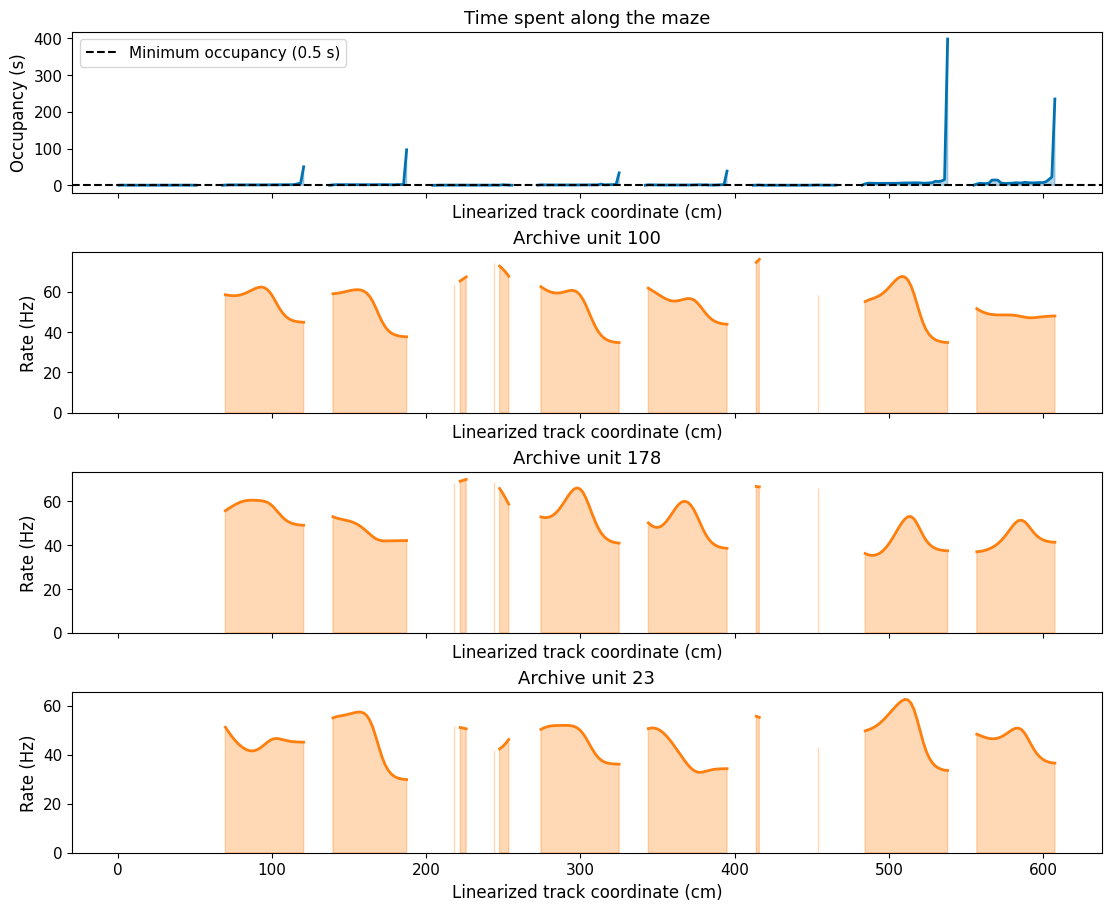

In [6]:
# Display track segments in order, with gaps between separate segments.
fig, axes = plt.subplots(4, 1, figsize=(11, 9), sharex=True, constrained_layout=True)
env.plot_field(rates.occupancy, ax=axes[0], colorbar_label="Occupancy (s)")
axes[0].axhline(0.5, color="black", linestyle="--", label="Minimum occupancy (0.5 s)")
axes[0].set(ylabel="Occupancy (s)", title="Time spent along the maze")
axes[0].legend()
for ax, unit_id in zip(axes[1:], example_units, strict=True):
    rates.sel(unit_id=unit_id).plot(ax=ax, color="tab:orange")
    ax.set(ylabel="Rate (Hz)", title=f"Archive unit {unit_id}", ylim=(0, None))
axes[-1].set(xlabel="Linearized track coordinate (cm)")
plt.show()

The rat spent much more time at some locations than others. Of 248 track
bins, 173 have enough occupancy for rate estimation. The three example units
fire across several segments; they were selected for spike count, not for
having a localized field. Their spatial information values describe these
maps and do not establish significant spatial tuning.

Gaps between displayed segments are for readability and add no travel
distance. Within a segment, a missing rate means insufficient occupancy.
Neither kind of blank space should be read as a measured zero firing rate.

## 4. Which arm ends are visited in succession?

Detect visits to the 8 cm arm-end zones, then pair entries into different
zones. Each interval starts at entry into the first zone and ends at entry
into the next. It includes any waiting after the first entry, so it is not
a departure-to-arrival running time or a task-defined trial. Changing the
zone radius changes these entry times.

Do not join visits across missing tracking. A visit already in progress when
recording starts has no observed entry and cannot start a pair. If the rat
re-enters the same zone before visiting another, use its last entry as the
start of the next pair.

In [7]:
position_bins = env.bin_at(positions)
visits = detect_region_visits(
    position_bins, times, env, region_names=arm_end_names, max_gap=max_gap
)
transitions = region_transitions(visits)
if not transitions:
    raise ValueError(
        "No movement between arm-end zones; inspect the tracking and regions."
    )
visit_table = pd.DataFrame(visits)
transition_table = pd.DataFrame(transitions)
counts = transition_table.groupby(["source_region", "target_region"]).size()
print(f"{len(visits)} visits; {visit_table.entry_observed.sum()} observed entries")
print(f"{len(transitions)} consecutive entries into different arm-end zones")
print(counts.sort_values(ascending=False).rename("count").to_string())

191 visits; 191 observed entries
180 consecutive entries into different arm-end zones
source_region  target_region
arm_end_5      arm_end_4        63
arm_end_4      arm_end_5        62
arm_end_0      arm_end_1        14
arm_end_1      arm_end_0        14
arm_end_2      arm_end_3         9
arm_end_3      arm_end_2         8
arm_end_1      arm_end_4         2
arm_end_2      arm_end_1         2
arm_end_4      arm_end_1         2
arm_end_1      arm_end_2         1
               arm_end_5         1
arm_end_3      arm_end_4         1
arm_end_4      arm_end_2         1


Most pairs in this recording link arm ends 4 and 5. These counts describe
observed movement; without trial and reward labels, they cannot tell us which
options were available or why the rat visited an arm.

## 5. How does position change between arm-end entries?

Plot the first three intervals on a common scale. At each sample, divide the
shortest track distance from the starting bin by the track distance between
the two entry bins, then limit the result to 0-1. This is `path_progress`.
Zero marks the start and one marks the reference distance to the destination.
On a branched maze, a detour can also reach that distance, so this quantity
alone does not establish arrival or an efficient route.

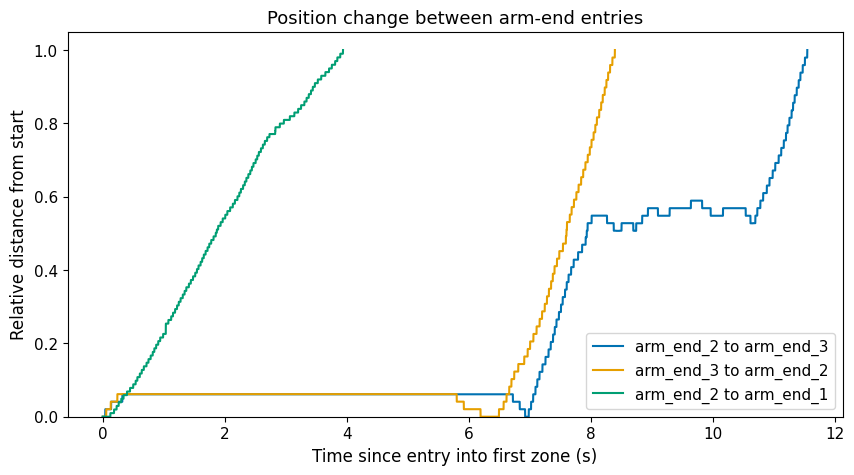

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
for transition in transitions[:3]:
    selected = np.arange(transition.start_index, transition.end_index + 1)
    progress = path_progress(
        position_bins[selected],
        env,
        start_bins=np.full(selected.size, position_bins[transition.start_index]),
        goal_bins=np.full(selected.size, position_bins[transition.end_index]),
        metric="geodesic",
    )
    np.testing.assert_allclose(progress[[0, -1]], [0.0, 1.0])
    ax.plot(
        times[selected] - transition.start_time,
        progress,
        label=f"{transition.source_region} to {transition.target_region}",
    )
ax.set(
    xlabel="Time since entry into first zone (s)",
    ylabel="Relative distance from start",
    title="Position change between arm-end entries",
    ylim=(0, 1.05),
)
ax.legend()
plt.show()

The flat portions show little change in distance from the starting bin;
the rising portions show movement farther from it. The intervals differ in
duration and include waiting. Their endpoints are 0 and 1 by construction,
rather than evidence for a particular movement strategy.

## Use your own recording

Supply spike times for each unit, tracking times and `(x, y)` positions on the
same clock, and a graph of the known track. Set the coordinate units before
choosing bin size, smoothing width and arm-end radius. Inspect tracking on
the maze, remove outliers, and use the actual spike-acquisition intervals.
Keep unit identifiers from spike sorting so maps can be matched to other
analyses. If your question concerns running or reward-related firing, define
running periods or trials from the relevant measurements before estimating
maps; the all-time maps here include waiting.

Report the occupancy rule and smoothing width with the maps. Add task logs
for trial and reward comparisons, and use appropriate controls before making
claims about significant spatial tuning or cell type.

Next, use [held-out decoding](06_position_decoding.ipynb) to evaluate prediction
on new observations or [peri-event analysis](07_peri_event_analysis.ipynb) to
align spikes to independently defined events.